# VKOSPI ≥ 18 × 낙폭과대주: 2026년 7~10월 Out-of-Sample 검증

**Frozen strategy / OOS evaluation** | 원본: `vkospi_disparity_reversal (1).ipynb` (2021~2026년 6월 분석)

> 목적: 과거에 정한 규칙을 변경하거나 7~10월 성과에 맞춰 재최적화하지 않고, 이후 기간 성과와 **실제 거래 대상 종목**을 확인한다.

| 구분 | 고정 규칙 |
|:--|:--|
| 종목 유니버스 | 첨부한 과거 노트북에 적힌 **200개 티커를 그대로 고정** |
| 시그널 | 신호일 종가 ÷ 직전 20거래일 종가 평균 × 100 |
| 선발 | 매월 마지막 거래일 신호로 이격도가 가장 낮은 **20개 종목** |
| 진입 | 같은 날 **VKOSPI 종가 ≥ 18**일 때만; 그 외 현금 |
| 체결 가정 | 신호일 **다음 거래일 시가 매수**, 한 달 뒤 다음 신호일의 다음 거래일 **시가 매도** |
| 비중 / 비용 | 종목당 5% 동일가중; 편도 20bp(기존 연구 가정) |
| OOS 실현손익 | **2026-06-30 신호 → 7월 매수**부터 시작. 7·8·9월 종료 거래는 실현 |
| 10월 | **2026-09-30 신호로 10월 1일 진입**, 10월 16일까지 평가손익(MTM) |

### 검증 규율

1. **종목 선정은 월말 신호일의 정보만 사용**한다. 다음 달 매도가격이나 상장생존 여부를 보고 종목을 바꾸지 않는다.
2. 시가가 없어서 주문 체결을 가정할 수 없으면 해당 종목의 **5%를 현금**으로 둔다. 매도가격이 없는 체결된 종목은 임의로 0% 수익 처리하지 않고 **오류로 중단**한다.
3. 10월의 미실현손익은 10월 16일 **종가** 기준(진입비용만 공제). 이후 월초 청산 시가 기준의 확정손익과 다르다.
4. 데이터와 유니버스의 한계: 기존 200개 종목은 과거 시점별 KOSPI200 편입이력이 아니다. 배당/기업행위 및 상장폐지, 호가·미체결 문제는 완전히 재현하지 못한다.
5. 이 결과는 **단기 OOS 관찰치 3개월+1개월 중간값**이지 전략의 통계적 검증 완료를 뜻하지 않는다.



## 0. 실행 순서 / 설치

- 권장: 로컬 **JupyterLab / VS Code**의 Python 3.10+ 커널.
- `vkospi.xlsx`는 사용자가 제시한 Windows 절대경로에서 먼저 찾고, 없으면 **노트북과 같은 폴더**에서 찾는다.
- `finance-datareader`에서 코스피200 지수와 약 200개 종목의 **일별 OHLC**를 새로 가져옵니다. 기존 노트북의 `kospi200_fdr_ohlcv.csv`는 **자동 신뢰하지 않으며**, 별도 OOS 캐시를 사용한다.
- 출력은 `oos_vkospi_results/` 폴더의 CSV로 저장합니다. 계좌 주문을 전송하는 노트북은 아니다.



In [1]:
%pip install -q finance-datareader pandas numpy matplotlib openpyxl tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import time
import warnings
import hashlib
import json
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import FinanceDataReader as fdr
from tqdm.auto import tqdm
from IPython.display import display

# 원본 학습 종료 이후 구간만 평가한다. 파라미터는 OOS 성과를 보고 수정하지 않는다.
OOS_MONTHS = pd.period_range("2026-07", "2026-10", freq="M")
ASOF = pd.Timestamp("2026-10-18")  # 일요일; 가장 최근 거래일은 10/16이어야 함
FETCH_START = "2026-05-01"         # 6월 신호의 MA20 계산을 위한 사전 자료
FETCH_END_EXCLUSIVE = "2026-10-19"
MA_WINDOW = 20
TOP_N = 20
VKOSPI_THRESHOLD = 18.0
ONE_WAY_COST_BPS = 20.0
MIN_SIGNAL_COVERAGE = 160         # 200개 중 시그널 계산 가능 종목 수 검증
PRICE_CACHE = Path("kospi200_fdr_ohlcv_oos.csv")
INDEX_CACHE = Path("ks200_fdr_ohlcv_oos.csv")
OUTPUT_DIR = Path("oos_vkospi_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VKOSPI_CANDIDATES = [
    Path(r"C:\Users\jesst\바탕 화면\매크로\download\vkospi.xlsx"),
    Path("vkospi.xlsx"),
]
VKOSPI_PATH = next((p for p in VKOSPI_CANDIDATES if p.is_file()), None)
if VKOSPI_PATH is None:
    raise FileNotFoundError("vkospi.xlsx를 이 노트북과 같은 폴더에 복사하거나 VKOSPI_CANDIDATES 경로를 수정하세요.")

print("VKOSPI 파일:", VKOSPI_PATH.resolve())
print("데이터 평가 종료일:", ASOF.date())
print("FDR 버전:", getattr(fdr, "__version__", "unknown"))

VKOSPI 파일: C:\Users\jesst\바탕 화면\매크로\download\vkospi.xlsx
데이터 평가 종료일: 2026-10-18
FDR 버전: 0.9.110


## 1. 학습 당시 사용한 유니버스 고정

아래 `STOCKS` 딕셔너리는 **첨부된 기존 노트북에서 그대로 복사**했습니다. 검증 중에는 편입·편출을 새로 적용하지 않습니다. 다만 이것은 2026년 6월 말 **실제 구성종목 편입이력**을 검증한 자료가 아니므로, 지수 구성종목 편향이 남아 있습니다.

In [14]:
STOCKS = {
    "005930": "삼성전자",
    "000660": "SK하이닉스",
    "402340": "SK스퀘어",
    "009150": "삼성전기",
    "005380": "현대차",
    "032830": "삼성생명",
    "028260": "삼성물산",
    "373220": "LG에너지솔루션",
    "207940": "삼성바이오로직스",
    "034730": "SK",
    "329180": "HD현대중공업",
    "034020": "두산에너빌리티",
    "012450": "한화에어로스페이스",
    "000270": "기아",
    "105560": "KB금융",
    "012330": "현대모비스",
    "055550": "신한지주",
    "006400": "삼성SDI",
    "068270": "셀트리온",
    "267260": "HD현대일렉트릭",
    "066570": "LG전자",
    "010120": "LS ELECTRIC",
    "042660": "한화오션",
    "035420": "NAVER",
    "086790": "하나금융지주",
    "298040": "효성중공업",
    "000810": "삼성화재",
    "042700": "한미반도체",
    "009540": "HD한국조선해양",
    "005490": "POSCO홀딩스",
    "015760": "한국전력",
    "000150": "두산",
    "006800": "미래에셋증권",
    "010130": "고려아연",
    "011070": "LG이노텍",
    "316140": "우리금융지주",
    "010140": "삼성중공업",
    "051910": "LG화학",
    "064350": "현대로템",
    "017670": "SK텔레콤",
    "033780": "KT&G",
    "011200": "HMM",
    "138040": "메리츠금융지주",
    "079550": "LIG넥스원",
    "267250": "HD현대",
    "096770": "SK이노베이션",
    "024110": "기업은행",
    "035720": "카카오",
    "003670": "포스코퓨처엠",
    "003550": "LG",
    "307950": "현대오토에버",
    "272210": "한화시스템",
    "018260": "삼성에스디에스",
    "278470": "에이피알",
    "086280": "현대글로비스",
    "047810": "한국항공우주",
    "030200": "KT",
    "000720": "현대건설",
    "071050": "한국금융지주",
    "006260": "LS",
    "010950": "S-Oil",
    "003490": "대한항공",
    "005940": "NH투자증권",
    "443060": "HD현대마린솔루션",
    "016360": "삼성증권",
    "323410": "카카오뱅크",
    "259960": "크래프톤",
    "005830": "DB손해보험",
    "039490": "키움증권",
    "003230": "삼양식품",
    "047050": "포스코인터내셔널",
    "028050": "삼성E&A",
    "047040": "대우건설",
    "352820": "하이브",
    "180640": "한진칼",
    "007660": "이수페타시스",
    "064400": "LG씨엔에스",
    "000880": "한화",
    "161390": "한국타이어앤테크놀로지",
    "062040": "산일전기",
    "004170": "신세계",
    "326030": "SK바이오팜",
    "000990": "DB하이텍",
    "001440": "대한전선",
    "021240": "코웨이",
    "034220": "LG디스플레이",
    "454910": "두산로보틱스",
    "078930": "GS",
    "032640": "LG유플러스",
    "241560": "두산밥캣",
    "090430": "아모레퍼시픽",
    "009830": "한화솔루션",
    "000100": "유한양행",
    "377300": "카카오페이",
    "267270": "HD건설기계",
    "011790": "SKC",
    "029780": "삼성카드",
    "138930": "BNK금융지주",
    "036570": "엔씨소프트",
    "128940": "한미약품",
    "271560": "오리온",
    "023530": "롯데쇼핑",
    "001040": "CJ",
    "002380": "KCC",
    "175330": "JB금융지주",
    "066970": "엘앤에프",
    "069960": "현대백화점",
    "082740": "한화엔진",
    "052690": "한전기술",
    "088350": "한화생명",
    "010060": "OCI홀딩스",
    "018880": "한온시스템",
    "004020": "현대제철",
    "051900": "LG생활건강",
    "022100": "포스코DX",
    "111770": "영원무역",
    "450080": "에코프로머티",
    "001450": "현대해상",
    "009420": "한올바이오파마",
    "035250": "강원랜드",
    "036460": "한국가스공사",
    "251270": "넷마블",
    "011780": "금호석유화학",
    "302440": "SK바이오사이언스",
    "483650": "달바글로벌",
    "011170": "롯데케미칼",
    "383220": "F&F",
    "014680": "한솔케미칼",
    "017800": "현대엘리베이터",
    "097950": "CJ제일제당",
    "012750": "에스원",
    "005850": "에스엘",
    "139130": "iM금융지주",
    "028670": "팬오션",
    "375500": "DL이앤씨",
    "004990": "롯데지주",
    "026960": "동서",
    "204320": "HL만도",
    "139480": "이마트",
    "009970": "영원무역홀딩스",
    "000240": "한국앤컴퍼니",
    "007340": "DN오토모티브",
    "457190": "이수스페셜티케미컬",
    "081660": "미스토홀딩스",
    "030000": "제일기획",
    "161890": "한국콜마",
    "282330": "BGF리테일",
    "051600": "한전KPS",
    "071970": "HD현대마린엔진",
    "004370": "농심",
    "093370": "후성",
    "008770": "호텔신라",
    "008930": "한미사이언스",
    "007070": "GS리테일",
    "103140": "풍산",
    "120110": "코오롱인더",
    "112610": "씨에스윈드",
    "011210": "현대위아",
    "000120": "CJ대한통운",
    "192820": "코스맥스",
    "002790": "아모레퍼시픽홀딩스",
    "001800": "오리온홀딩스",
    "017960": "한국카본",
    "006280": "녹십자",
    "006040": "동원산업",
    "069620": "대웅제약",
    "073240": "금호타이어",
    "192080": "더블유게임즈",
    "361610": "SK아이이테크놀로지",
    "001430": "세아베스틸지주",
    "034230": "파라다이스",
    "298020": "효성티앤씨",
    "007310": "오뚜기",
    "004000": "롯데정밀화학",
    "000080": "하이트진로",
    "300720": "한일시멘트",
    "003090": "대웅",
    "185750": "종근당",
    "000210": "DL",
    "003240": "태광산업",
    "005300": "롯데칠성",
    "280360": "롯데웰푸드",
    "456040": "OCI",
    "071320": "지역난방공사",
    "009240": "한샘",
    "000670": "영풍",
    "298050": "HS효성첨단소재",
    "006650": "대한유화",
    "137310": "에스디바이오센서",
    "285130": "SK케미칼",
    "069260": "TKG휴켐스",
    "001680": "대상",
    "002840": "미원상사",
    "014820": "동원시스템즈",
    "268280": "미원에스씨",
    "003030": "세아제강지주",
    "005420": "코스모화학",
    "008730": "율촌화학",
    "002030": "아세아",
    "0126Z0": "삼성에피스홀딩스"
}
assert len(STOCKS) == 200, "원본 티커 리스트가 변경되었습니다."
assert len(set(STOCKS)) == 200
UNIVERSE_HASH = hashlib.sha256(json.dumps(STOCKS, ensure_ascii=False, sort_keys=True).encode()).hexdigest()[:16]
print(f"Frozen universe: {len(STOCKS)} tickers | hash={UNIVERSE_HASH}")

Frozen universe: 200 tickers | hash=a60a75095e1bb6ae


## 2. VKOSPI 읽기 / 날짜 형식 검사

`일자`, `종가`를 사용

In [15]:
def parse_excel_date(x):
    if pd.isna(x):
        return pd.NaT
    if isinstance(x, (pd.Timestamp, dt.datetime, dt.date)):
        return pd.Timestamp(x).normalize()
    if isinstance(x, (int, float, np.integer, np.floating)):
        return pd.Timestamp("1899-12-30") + pd.to_timedelta(float(x), unit="D")
    s = str(x).strip()
    if s.replace(".", "", 1).isdigit() and float(s) > 30000:
        return pd.Timestamp("1899-12-30") + pd.to_timedelta(float(s), unit="D")
    return pd.to_datetime(s, errors="coerce")

raw_vk = pd.read_excel(VKOSPI_PATH)
if not {"일자", "종가"}.issubset(raw_vk.columns):
    raise ValueError(f"VKOSPI 파일에 '일자', '종가'가 없습니다. 실제 열: {raw_vk.columns.tolist()}")
vk = pd.DataFrame({
    "date": raw_vk["일자"].map(parse_excel_date),
    "vkospi": pd.to_numeric(raw_vk["종가"].astype(str).str.replace(",", ""), errors="coerce"),
}).dropna(subset=["date", "vkospi"])
vk["date"] = pd.to_datetime(vk["date"]).dt.normalize()
vk = vk.sort_values("date").drop_duplicates("date", keep="last").set_index("date")["vkospi"]
vk = vk.loc[:ASOF]
assert (vk > 0).all()
print(f"VKOSPI: {vk.index.min().date()} ~ {vk.index.max().date()} ({len(vk):,} rows)")
print("최신 값:")
display(vk.tail(7).to_frame())

VKOSPI: 2005-01-05 ~ 2026-10-16 (4,885 rows)
최신 값:


,vkospi
date,
2026-10-07,38.11
2026-10-08,36.81
2026-10-12,40.73
2026-10-13,48.53
2026-10-14,44.91
2026-10-15,55.38
2026-10-16,48.89


## 3. KOSPI200 거래일 / 주가 수집

- 캘린더는 FDR의 `KS200`을 사용합니다 (`^KS200`이 아님).
- 종목별 OHLC는 동일한 2026년 5~10월 구간으로 수집합니다.
- 수집 실패 종목은 목록으로 출력합니다. **최소 160개 이상 신호 자료**를 확보하지 못하면 검증을 중단합니다.
- **캐시 재사용**: 원하는 최신 거래일까지 존재하는 티커는 다시 내려받지 않습니다. 진행 중 끊겨도 중간저장한 CSV부터 이어서 실행할 수 있습니다.

In [16]:
def standardize_ohlc(raw):
    if raw is None or len(raw) == 0:
        return pd.DataFrame(columns=["date", "open", "close"])
    x = raw.reset_index().copy()
    date_col = "Date" if "Date" in x.columns else ("date" if "date" in x.columns else x.columns[0])
    x = x.rename(columns={date_col: "date", "Open": "open", "Close": "close"})
    need = {"date", "open", "close"}
    if not need.issubset(x.columns):
        raise ValueError(f"OHLC 열 부족: {x.columns.tolist()}")
    x["date"] = pd.to_datetime(x["date"]).dt.tz_localize(None).dt.normalize()
    for c in ["open", "close"]:
        x[c] = pd.to_numeric(x[c], errors="coerce")
    x = x[(x["date"] <= ASOF) & (x["date"] >= pd.Timestamp(FETCH_START))]
    return x[["date", "open", "close"]].sort_values("date").drop_duplicates("date", keep="last")

# 지수는 신호일의 정확한 거래일, 매매 실행일, 벤치마크 가격에 사용
try:
    ks = standardize_ohlc(fdr.DataReader("KS200", FETCH_START, FETCH_END_EXCLUSIVE))
    ks.to_csv(INDEX_CACHE, index=False, encoding="utf-8-sig")
except Exception as exc:
    if not INDEX_CACHE.is_file():
        raise RuntimeError(f"KS200 데이터를 내려받지 못했습니다: {exc}") from exc
    warnings.warn(f"KS200 다운로드 실패 → 로컬 캐시 사용: {exc}")
    ks = standardize_ohlc(pd.read_csv(INDEX_CACHE))

ks = ks[(ks["open"] > 0) & (ks["close"] > 0)].set_index("date").sort_index()
if ks.empty or ks.index.max() < pd.Timestamp("2026-10-16"):
    raise RuntimeError(f"KS200 자료가 10월 16일까지 없습니다. 최신: {ks.index.max() if not ks.empty else 'EMPTY'}")

last_market_day = ks.index.max()
print("KS200 마지막 거래일:", last_market_day.date())
print("VKOSPI 마지막 자료일:", vk.index.max().date())
if vk.index.max() < last_market_day:
    raise RuntimeError("VKOSPI 자료가 지수 최신 거래일보다 오래됐습니다. 업데이트 파일이 필요합니다.")

if PRICE_CACHE.is_file():
    cached = pd.read_csv(PRICE_CACHE, dtype={"ticker": str}, parse_dates=["date"])
    cached["date"] = pd.to_datetime(cached["date"]).dt.normalize()
else:
    cached = pd.DataFrame(columns=["ticker", "name", "date", "open", "close"])

required_cols = ["ticker", "name", "date", "open", "close"]
for c in required_cols:
    if c not in cached.columns:
        raise ValueError(f"가격 캐시 CSV에 '{c}'가 없습니다. 캐시를 삭제하고 다시 실행하세요.")

pieces = [cached]
cache_dates = cached.groupby("ticker")["date"].max().to_dict() if not cached.empty else {}
failed = []
to_download = [t for t in STOCKS if t not in cache_dates or pd.Timestamp(cache_dates[t]) < last_market_day]
print(f"다운로드 대상 {len(to_download)}개 / 캐시 완료 {len(STOCKS)-len(to_download)}개")
for j, ticker in enumerate(tqdm(to_download, desc="FDR stock prices"), start=1):
    try:
        data = standardize_ohlc(fdr.DataReader(ticker, FETCH_START, FETCH_END_EXCLUSIVE))
        if data.empty:
            failed.append({"ticker": ticker, "name": STOCKS[ticker], "reason": "EMPTY"})
            continue
        data.insert(0, "name", STOCKS[ticker])
        data.insert(0, "ticker", ticker)
        pieces.append(data)
    except Exception as exc:
        failed.append({"ticker": ticker, "name": STOCKS[ticker], "reason": str(exc)[:180]})
    if j % 20 == 0:
        interim = pd.concat(pieces, ignore_index=True)
        interim = interim.drop_duplicates(["ticker", "date"], keep="last")
        interim.to_csv(PRICE_CACHE, index=False, encoding="utf-8-sig")
    time.sleep(0.08)

prices = pd.concat(pieces, ignore_index=True)
prices["date"] = pd.to_datetime(prices["date"]).dt.normalize()
for c in ["open", "close"]:
    prices[c] = pd.to_numeric(prices[c], errors="coerce")
prices = prices.drop_duplicates(["ticker", "date"], keep="last")
prices = prices[(prices["ticker"].isin(STOCKS)) & (prices["date"] <= last_market_day)]
prices = prices.sort_values(["ticker", "date"]).reset_index(drop=True)
prices.to_csv(PRICE_CACHE, index=False, encoding="utf-8-sig")

if failed:
    print(f"다운로드 오류/상장 이슈: {len(failed)}개")
    display(pd.DataFrame(failed).head(25))
    pd.DataFrame(failed).to_csv(OUTPUT_DIR / "download_failures.csv", index=False, encoding="utf-8-sig")
print(f"가격 데이터: {prices['ticker'].nunique()} tickers, {len(prices):,} rows, latest {prices['date'].max().date()}")
assert prices["ticker"].nunique() >= MIN_SIGNAL_COVERAGE, "데이터 수집 실패 종목이 많습니다. 정상 OHLC 확보 후 진행하세요."

KS200 마지막 거래일: 2026-10-16
VKOSPI 마지막 자료일: 2026-10-16
다운로드 대상 0개 / 캐시 완료 200개


FDR stock prices: 0it [00:00, ?it/s]

가격 데이터: 200 tickers, 22,200 rows, latest 2026-10-16


## 4. 신호일에만 종목 선정하고, 그 뒤에 체결/평가

월말별 이격도는 해당 날짜까지 자료만 사용한다. 
**다음 달 시가를 활용해 선정 종목 자체를 바꾸지 않는다.** 거래 정지 등의 이유로 시가로 체결할 수 없다면 5% 배분 양을 현금으로 보유한 것으로 처리한다.

- 7월 보유: 6월 말 신호 → 7월 첫 거래일 매수 → 8월 첫 거래일 매도
- 8월 보유: 7월 말 신호 → 8월 첫 거래일 매수 → 9월 첫 거래일 매도
- 9월 보유: 8월 말 신호 → 9월 첫 거래일 매수 → 10월 첫 거래일 매도
- 10월 보유: 9월 말 신호 → 10월 첫 거래일 매수 → 10월 16일 **종가 평가**

In [17]:
def prepare_signal_frame(stock_prices):
    x = stock_prices.sort_values(["ticker", "date"]).copy()
    x.loc[x["close"] <= 0, "close"] = np.nan
    x.loc[x["open"] <= 0, "open"] = np.nan
    x["ma20"] = x.groupby("ticker")["close"].transform(
        lambda z: z.rolling(MA_WINDOW, min_periods=MA_WINDOW).mean()
    )
    x["disparity"] = 100 * x["close"] / x["ma20"]
    return x

sig_data = prepare_signal_frame(prices)
lookup = sig_data.set_index(["date", "ticker"]).sort_index()

# 인덱스와 시계열 자료의 날짜가 일치하지 않을 때 허위 가격 보간은 하지 않는다.
def get_stock_row(day, ticker):
    try:
        z = lookup.loc[(pd.Timestamp(day), ticker)]
        return z.iloc[0] if isinstance(z, pd.DataFrame) else z
    except KeyError:
        return None

def get_trading_period(month):
    sessions = ks.index
    first_sessions = sessions[sessions.to_period("M") == month]
    if not len(first_sessions):
        raise RuntimeError(f"{month} KOSPI200 거래일 정보 없음")
    entry = first_sessions.min()
    before = sessions[sessions < entry]
    if not len(before):
        raise RuntimeError(f"{month} 직전 월말 신호일 자료 없음")
    signal = before.max()
    # 다음 달 첫 거래일: 반드시 그 달이 종료되고 실제 날짜가 관측된 경우에만 사용
    later = sessions[sessions > first_sessions.max()]
    complete = len(later) > 0 and later.min().to_period("M") > month
    exit_or_mark = later.min() if complete else sessions.max()
    return signal, entry, exit_or_mark, complete

coverage_rows = []
for m in OOS_MONTHS:
    signal, entry, end, complete = get_trading_period(m)
    v = vk.get(signal, np.nan)
    candidates = sig_data[(sig_data["date"] == signal) & sig_data["disparity"].notna() & (sig_data["close"] > 0)]
    coverage_rows.append({"month":str(m), "signal":signal.date(), "entry":entry.date(),
                          "exit_or_mark":end.date(), "complete":bool(complete),
                          "VKOSPI":v, "valid_signal_stocks":len(candidates)})
coverage = pd.DataFrame(coverage_rows)
display(coverage)
if coverage["VKOSPI"].isna().any():
    raise RuntimeError("월말 VKOSPI 값이 빠져 있습니다. 신호일과 VKOSPI 자료를 확인하세요.")
if coverage["valid_signal_stocks"].min() < MIN_SIGNAL_COVERAGE:
    raise RuntimeError("월말 이격도 계산 가능한 종목이 160개 미만입니다. 다운받은 시세를 확인하세요.")
assert coverage["complete"].tolist() == [True, True, True, False], "7~9월 완료, 10월 미완료 구분이 예상과 다릅니다."

PARAMS = {"ma_window":MA_WINDOW, "top_n":TOP_N, "threshold":VKOSPI_THRESHOLD,
          "cost_one_way_bps":ONE_WAY_COST_BPS, "oos_months":[str(m) for m in OOS_MONTHS],
          "asof":str(ASOF.date()), "universe_sha256_16":UNIVERSE_HASH}
(OUTPUT_DIR / "frozen_config.json").write_text(json.dumps(PARAMS, indent=2, ensure_ascii=False), encoding="utf-8")

,month,signal,entry,exit_or_mark,complete,VKOSPI,valid_signal_stocks
0,2026-07,2026-06-30,2026-07-01,2026-08-03,True,93.80,200
1,2026-08,2026-07-31,2026-08-03,2026-09-01,True,84.35,200
2,2026-09,2026-08-31,2026-09-01,2026-10-01,True,46.05,200
3,2026-10,2026-09-30,2026-10-01,2026-10-16,False,43.03,200


235

In [18]:
def evaluate_oos(threshold=VKOSPI_THRESHOLD, cost_bps=ONE_WAY_COST_BPS):
    monthly_rows, trade_rows, all_candidates = [], [], []
    for month in OOS_MONTHS:
        signal, entry, exit_or_mark, complete = get_trading_period(month)
        v = float(vk.loc[signal])
        candidates = sig_data.loc[
            (sig_data["date"] == signal) & sig_data["disparity"].notna() & (sig_data["close"] > 0)
        ].sort_values(["disparity", "ticker"]).copy()
        if len(candidates) < MIN_SIGNAL_COVERAGE:
            raise RuntimeError(f"{month}: 유효 이격도 종목 {len(candidates)}개, 재실행 필요")
        selected = candidates.head(TOP_N).copy()
        selected["rank"] = np.arange(1, len(selected) + 1)
        selected["month"] = str(month)
        all_candidates.append(selected[["month", "date", "rank", "ticker", "name", "close", "ma20", "disparity"]])
        invested = (threshold is None) or (v >= threshold)
        gross_contribution, cost_contribution, unfilled = 0.0, 0.0, 0
        if invested:
            for r in selected.itertuples():
                buyrow = get_stock_row(entry, r.ticker)
                buy_px = float(buyrow["open"]) if buyrow is not None and pd.notna(buyrow["open"]) else np.nan
                # 체결 없으면 5% 현금, 다른 종목으로 대체하지 않음
                filled = np.isfinite(buy_px) and buy_px > 0
                sell_px = np.nan
                reason = "FILLED" if filled else "NO_ENTRY_OPEN__CASH"
                gross = 0.0
                entry_cost = 0.0
                exit_cost = 0.0
                if filled:
                    sellrow = get_stock_row(exit_or_mark, r.ticker)
                    price_col = "open" if complete else "close"
                    sell_px = float(sellrow[price_col]) if sellrow is not None and pd.notna(sellrow[price_col]) else np.nan
                    if not np.isfinite(sell_px) or sell_px <= 0:
                        raise RuntimeError(
                            f"{month}: 실제 진입한 {r.ticker}({r.name})의 {exit_or_mark.date()} "
                            f"{'매도 시가' if complete else '평가 종가'}가 없습니다. "
                            "거래정지/상장폐지/주가 데이터 오류를 확인하세요. 임의 수익률로 대체하지 않습니다."
                        )
                    gross = sell_px / buy_px - 1
                    entry_cost = cost_bps / 10_000
                    exit_cost = (cost_bps / 10_000) if complete else 0.0
                else:
                    unfilled += 1
                weight = 1 / TOP_N
                net = gross - entry_cost - exit_cost
                gross_contribution += weight * gross
                cost_contribution += weight * (entry_cost + exit_cost)
                trade_rows.append({
                    "holding_month":str(month), "signal_date":signal, "entry_date":entry,
                    "exit_or_mark_date":exit_or_mark, "status":"REALIZED" if complete else "UNREALIZED_MTM",
                    "ticker":r.ticker, "name":r.name, "rank":int(r.rank),
                    "vkospi_signal":v, "disparity_signal":float(r.disparity), "weight_target":weight,
                    "entry_open":buy_px, "exit_open_or_mark_close":sell_px,
                    "filled":filled, "trade_note":reason,
                    "gross_stock_return":gross if filled else np.nan,
                    "net_stock_return":net if filled else np.nan,
                    "portfolio_contribution_net":weight * net,
                })
        idx_start = ks.loc[entry,"open"]
        idx_end = ks.loc[exit_or_mark, "open" if complete else "close"]
        benchmark_return = float(idx_end / idx_start - 1)
        monthly_rows.append({
            "holding_month":str(month), "signal_date":signal, "entry_date":entry,
            "exit_or_mark_date":exit_or_mark, "status":"REALIZED" if complete else "UNREALIZED_MTM",
            "vkospi_signal":v, "invested":bool(invested), "selected_n":TOP_N if invested else 0,
            "unfilled_n":unfilled, "gross_return":gross_contribution,
            "total_cost_fraction":cost_contribution, "strategy_return":gross_contribution-cost_contribution,
            "kospi200_return":benchmark_return,
        })
    mdf = pd.DataFrame(monthly_rows)
    mdf["strategy_nav"] = (1 + mdf["strategy_return"]).cumprod()
    mdf["kospi200_nav"] = (1 + mdf["kospi200_return"]).cumprod()
    trades_df = pd.DataFrame(trade_rows)
    selections_df = pd.concat(all_candidates, ignore_index=True)
    return mdf, trades_df, selections_df

monthly, trades, selections = evaluate_oos()
monthly_nofilter, trades_nofilter, _ = evaluate_oos(threshold=None)
# monthly["no_filter_return"] = monthly_nofilter["strategy_return"].to_numpy()
# monthly["no_filter_nav"] = (1 + monthly["no_filter_return"]).cumprod()

display(monthly[["holding_month","signal_date","vkospi_signal","invested","status",
                 "strategy_return",
                 # "no_filter_return",
                 "kospi200_return","strategy_nav"]].style.format({
    "strategy_return":"{:+.2%}",
    # "no_filter_return":"{:+.2%}",
    "kospi200_return":"{:+.2%}","strategy_nav":"{:.4f}","vkospi_signal":"{:.2f}"}))

,holding_month,signal_date,vkospi_signal,invested,status,strategy_return,kospi200_return,strategy_nav
0,2026-07,2026-06-30 00:00:00,93.80,True,REALIZED,-16.18%,-27.61%,0.8382
1,2026-08,2026-07-31 00:00:00,84.35,True,REALIZED,+24.17%,+5.96%,1.0408
2,2026-09,2026-08-31 00:00:00,46.05,True,REALIZED,-2.78%,+1.12%,1.0118
3,2026-10,2026-09-30 00:00:00,43.03,True,UNREALIZED_MTM,-7.83%,-18.49%,0.9326


## 5. 성과 리포트: 실현과 평가손익 분리

미실현 10월 값을 포함한 누적수익률을 별도로 계산합니다. OOS 기간은 4개월 미만이어서 Sharpe/CAGR/t-test를 성급하게 연율화하지 않습니다.

=== OOS performance ===


,strategy,realized_Jul_Sep,through_Oct16_MTM,invested_months
0,VKOSPI >= 18,+1.18%,-6.74%,4
1,No VKOSPI filter,+1.18%,-6.74%,4
2,KOSPI200 (price index),-22.43%,-36.77%,4


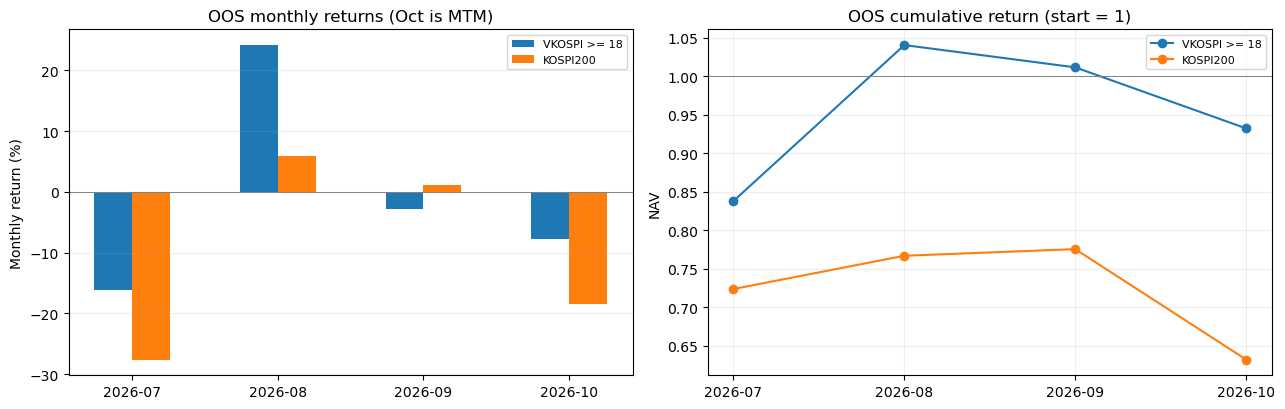

In [24]:
def cumul(ret):
    return float((1 + pd.Series(ret)).prod() - 1)

complete_rows = monthly[monthly["status"] == "REALIZED"].copy()
summary = pd.DataFrame([
    {"strategy":"VKOSPI >= 18", "realized_Jul_Sep":cumul(complete_rows["strategy_return"]),
     "through_Oct16_MTM":cumul(monthly["strategy_return"]),
     "invested_months":int(monthly["invested"].sum())},
    {"strategy":"No VKOSPI filter", "realized_Jul_Sep":cumul(monthly_nofilter[monthly_nofilter["status"]=="REALIZED"]["strategy_return"]),
     "through_Oct16_MTM":cumul(monthly_nofilter["strategy_return"]),
     "invested_months":int(monthly_nofilter["invested"].sum())},
    {"strategy":"KOSPI200 (price index)", "realized_Jul_Sep":cumul(complete_rows["kospi200_return"]),
     "through_Oct16_MTM":cumul(monthly["kospi200_return"]),
     "invested_months":len(monthly)},
])
print("=== OOS performance ===")
display(summary.style.format({"realized_Jul_Sep":"{:+.2%}", "through_Oct16_MTM":"{:+.2%}"}))

fig, axes = plt.subplots(1,2,figsize=(13,4.2))
xs = monthly["holding_month"]
axes[0].bar(np.arange(len(xs))-0.13, monthly["strategy_return"].values*100, width=.26, label="VKOSPI >= 18")
# axes[0].bar(np.arange(len(xs)), monthly["no_filter_return"].values*100,width=.26,label="No filter")
axes[0].bar(np.arange(len(xs))+0.13, monthly["kospi200_return"].values*100,width=.26,label="KOSPI200")
axes[0].set_xticks(np.arange(len(xs)),xs)
axes[0].set_ylabel("Monthly return (%)")
axes[0].set_title("OOS monthly returns (Oct is MTM)")
axes[0].axhline(0,c='gray',lw=.7)
axes[0].grid(axis='y',alpha=.2)
axes[0].legend(fontsize=8)
axes[1].plot(xs, monthly["strategy_nav"], marker='o',label="VKOSPI >= 18")
# axes[1].plot(xs, monthly["no_filter_nav"],marker='o',label="No filter")
axes[1].plot(xs, monthly["kospi200_nav"],marker='o',label="KOSPI200")
axes[1].axhline(1,c='gray',lw=.7)
axes[1].set_title("OOS cumulative return (start = 1)")
axes[1].set_ylabel("NAV")
axes[1].grid(alpha=.2)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. 실제 선발 종목 / 10월 보유목록

**7~10월 실거래 가정에 따른 종목별 명세**를 출력합니다. 10월은 9월 30일에 선정한 종목을 10월 첫 거래일 시가에 샀다고 가정한 **보유 포지션**입니다. 10월 16일에 새로 진입하라는 신호가 아닙니다.

In [25]:
for m in OOS_MONTHS:
    key = str(m)
    row = monthly.loc[monthly["holding_month"]==key].iloc[0]
    print(f"\n=== {key}: signal={pd.Timestamp(row['signal_date']).date()}, "
          f"VKOSPI={row['vkospi_signal']:.2f}, invested={row['invested']}, "
          f"return={row['strategy_return']:+.2%}, {row['status']} ===")
    picks = selections.loc[selections["month"]==key, ["rank","ticker","name","disparity"]]
    display(picks.style.format({"disparity":"{:.2f}"}))

print("\n--- OCTOBER OPEN POSITIONS (entry open → Oct16 close) ---")
if not trades.empty:
    open_positions = trades.loc[trades["holding_month"]=="2026-10", [
        "ticker","name","weight_target","disparity_signal","entry_open",
        "exit_open_or_mark_close","gross_stock_return","net_stock_return","portfolio_contribution_net","filled"
    ]]
    display(open_positions.style.format({
        "weight_target":"{:.1%}", "disparity_signal":"{:.2f}",
        "entry_open":"{:,.0f}", "exit_open_or_mark_close":"{:,.0f}",
        "gross_stock_return":"{:+.2%}","net_stock_return":"{:+.2%}",
        "portfolio_contribution_net":"{:+.2%}"
    },na_rep="-"))
else:
    print("10월 월말 신호에 진입하지 않았습니다.")


=== 2026-07: signal=2026-06-30, VKOSPI=93.80, invested=True, return=-16.18%, REALIZED ===


,rank,ticker,name,disparity
0,1,307950,현대오토에버,79.08
1,2,272210,한화시스템,81.43
2,3,001430,세아베스틸지주,81.69
3,4,454910,두산로보틱스,81.74
4,5,010060,OCI홀딩스,82.01
5,6,022100,포스코DX,82.59
6,7,005380,현대차,83.13
7,8,064400,LG씨엔에스,83.71
8,9,267250,HD현대,83.79
9,10,011790,SKC,83.82



=== 2026-08: signal=2026-07-31, VKOSPI=84.35, invested=True, return=+24.17%, REALIZED ===


,rank,ticker,name,disparity
20,1,004170,신세계,75.39
21,2,011070,LG이노텍,78.17
22,3,000990,DB하이텍,79.68
23,4,069960,현대백화점,80.16
24,5,093370,후성,82.19
25,6,352820,하이브,82.46
26,7,023530,롯데쇼핑,83.16
27,8,009150,삼성전기,83.20
28,9,047040,대우건설,83.34
29,10,007660,이수페타시스,83.51



=== 2026-09: signal=2026-08-31, VKOSPI=46.05, invested=True, return=-2.78%, REALIZED ===


,rank,ticker,name,disparity
40,1,111770,영원무역,87.90
41,2,079550,LIG넥스원,91.59
42,3,012330,현대모비스,91.75
43,4,009970,영원무역홀딩스,92.09
44,5,329180,HD현대중공업,93.01
45,6,009540,HD한국조선해양,93.34
46,7,047810,한국항공우주,94.28
47,8,483650,달바글로벌,94.62
48,9,015760,한국전력,94.66
49,10,069960,현대백화점,95.09



=== 2026-10: signal=2026-09-30, VKOSPI=43.03, invested=True, return=-7.83%, UNREALIZED_MTM ===


,rank,ticker,name,disparity
60,1,298020,효성티앤씨,84.94
61,2,009420,한올바이오파마,88.56
62,3,280360,롯데웰푸드,90.13
63,4,004170,신세계,90.40
64,5,241560,두산밥캣,90.62
65,6,267250,HD현대,90.71
66,7,271560,오리온,91.26
67,8,377300,카카오페이,91.29
68,9,282330,BGF리테일,91.40
69,10,006650,대한유화,91.40



--- OCTOBER OPEN POSITIONS (entry open → Oct16 close) ---


,ticker,name,weight_target,disparity_signal,entry_open,exit_open_or_mark_close,gross_stock_return,net_stock_return,portfolio_contribution_net,filled
60,298020,효성티앤씨,5.0%,84.94,"278,500","270,500",-2.87%,-3.07%,-0.15%,True
61,009420,한올바이오파마,5.0%,88.56,"43,900","42,400",-3.42%,-3.62%,-0.18%,True
62,280360,롯데웰푸드,5.0%,90.13,"123,400","121,200",-1.78%,-1.98%,-0.10%,True
63,004170,신세계,5.0%,90.40,"335,500","276,000",-17.73%,-17.93%,-0.90%,True
64,241560,두산밥캣,5.0%,90.62,"55,100","51,100",-7.26%,-7.46%,-0.37%,True
65,267250,HD현대,5.0%,90.71,"201,000","158,600",-21.09%,-21.29%,-1.06%,True
66,271560,오리온,5.0%,91.26,"106,900","108,700",+1.68%,+1.48%,+0.07%,True
67,377300,카카오페이,5.0%,91.29,"39,550","35,750",-9.61%,-9.81%,-0.49%,True
68,282330,BGF리테일,5.0%,91.40,"129,300","136,000",+5.18%,+4.98%,+0.25%,True
69,006650,대한유화,5.0%,91.40,"88,900","84,500",-4.95%,-5.15%,-0.26%,True


## 7. 최신 값으로 예비 순위 확인 (**정식 시그널 아님, 참고용 - 만약 지금 산다면?**)

10월 16일 가격과 VKOSPI는 다음 월말 신호가 나올 때까지 바뀔 수 있습니다. 아래는 **당일 참고용 순위**일 뿐, 원래 전략의 월말 리밸런싱 시그널이 아닙니다. 10월 말 정식 선정은 월말 거래 종료 후 다시 실행/업데이트해야 합니다.

In [26]:
last_day = min(sig_data["date"].max(), vk.index.max(), last_market_day)
preview = sig_data.loc[(sig_data["date"]==last_day) & sig_data["disparity"].notna()].sort_values(["disparity","ticker"]).head(TOP_N)
print(f"As of {last_day.date()} | VKOSPI={vk.loc[last_day]:.2f} | PROVISIONAL ONLY")
display(preview[["ticker","name","close","ma20","disparity"]].reset_index(drop=True).style.format({
    "close":"{:,.0f}", "ma20":"{:,.0f}","disparity":"{:.2f}"}))
print("이 목록으로 10/16 종가 직후 즉시 매수하는 거래는 원래 전략 규칙과 다릅니다.")

As of 2026-10-16 | VKOSPI=48.89 | PROVISIONAL ONLY


,ticker,name,close,ma20,disparity
0,298040,효성중공업,"1,944,000","2,611,000",74.45
1,000660,SK하이닉스,"1,265,000","1,692,250",74.75
2,402340,SK스퀘어,"782,000","1,040,950",75.12
3,000150,두산,"1,017,000","1,329,750",76.48
4,267270,HD건설기계,"92,300","119,995",76.92
5,011070,LG이노텍,"405,500","527,050",76.94
6,006260,LS,"228,500","289,725",78.87
7,267260,HD현대일렉트릭,"513,000","649,600",78.97
8,375500,DL이앤씨,"59,900","75,470",79.37
9,001430,세아베스틸지주,"35,650","44,168",80.72


이 목록으로 10/16 종가 직후 즉시 매수하는 거래는 원래 전략 규칙과 다릅니다.


## 8. 결과 저장 및 데이터 품질 요약

출력 파일:
- `oos_monthly_returns.csv`: 7~10월 월별 거래 및 성과
- `oos_trades.csv`: 실제 진입조건 충족 시 종목별 주문가/평가/기여도
- `oos_selected_20_each_month.csv`: 필터 충족과 관계없이 월별 20종목 후보
- `oos_no_filter_monthly.csv`: VKOSPI 필터 제거 시 월별 성과
- `oos_summary.csv`: OOS 전체 성과 비교
- `latest_provisional_ranking.csv`: 최신 거래일 예비 순위(정식 신호 아님)
- `frozen_config.json`: 사용한 전략 설정·유니버스 해시

CSV가 Excel에서 열리도록 UTF-8 BOM으로 저장합니다.

In [27]:
def export_csv(df, name):
    target = OUTPUT_DIR / name
    df.to_csv(target, index=False, encoding="utf-8-sig")
    print("Saved:", target.resolve())

export_csv(monthly, "oos_monthly_returns.csv")
export_csv(trades, "oos_trades.csv")
export_csv(selections, "oos_selected_20_each_month.csv")
# export_csv(monthly_nofilter, "oos_no_filter_monthly.csv")
export_csv(summary, "oos_summary.csv")
export_csv(preview[["date","ticker","name","close","ma20","disparity"]], "latest_provisional_ranking.csv")

print("\nData status:")
print(f"Frozen tickers={len(STOCKS)} | observed tickers={prices['ticker'].nunique()} | "
      f"asof={last_market_day.date()} | VKOSPI={vk.loc[last_market_day]:.2f}")
print("Realized months:", complete_rows["holding_month"].tolist())
print("MTM months:",monthly.loc[monthly["status"]=="UNREALIZED_MTM","holding_month"].tolist())
print("Unfilled positions:",int(monthly["unfilled_n"].sum()))

Saved: C:\Users\jesst\oos_vkospi_results\oos_monthly_returns.csv
Saved: C:\Users\jesst\oos_vkospi_results\oos_trades.csv
Saved: C:\Users\jesst\oos_vkospi_results\oos_selected_20_each_month.csv
Saved: C:\Users\jesst\oos_vkospi_results\oos_summary.csv
Saved: C:\Users\jesst\oos_vkospi_results\latest_provisional_ranking.csv

Data status:
Frozen tickers=200 | observed tickers=200 | asof=2026-10-16 | VKOSPI=48.89
Realized months: ['2026-07', '2026-08', '2026-09']
MTM months: ['2026-10']
Unfilled positions: 0


## 📌 결과를 볼 때 참고할 점

- **기존 보고서(2021~2026.06) 성과와는 별개다.**
  이 노트북은 2026년 6월 말 신호부터 시작하는 순수 OOS 검증용이므로, 앞 구간 수익률과 이어 붙여 보지 않는다.

- **수익률 계산 기준**
  - 7~9월: 매월 첫 거래일 시가 → 다음 달 첫 거래일 시가
  - 10월: 첫 거래일 시가 → 10/16 종가 (평가손익 기준)

  구간마다 기준이 정해져 있어, 시가·종가를 섞어 비교하면 숫자가 달라질 수 있다.

- **데이터 한계**
  FDR 가격 데이터는 상장폐지, 거래정지, 세부 거래세까지 완벽하게 반영하지 못한다. 미체결·누락 종목은 별도로 확인이 필요하다.

- **파라미터는 사전에 고정했다.**
  VKOSPI 필터 18 / 상위 20종목 / 20일 이평 / 편도 20bp는 검증 전에 정해둔 값이다. 7~10월 결과를 보고 다시 튜닝하면 더 이상 OOS라고 보기 어렵다.

- **연구용 백테스트다.**
  실제 주문이나 증권사 API 연동 기능은 없다. 실전에 쓰려면 별도 검증이 필요하다.

## 📂 Data
- **VKOSPI**: KRX 정보데이터시스템에서 엑셀 다운로드
- **개별 종목 · KOSPI200**: [FinanceDataReader](https://github.com/FinanceData/FinanceDataReader) / KRX 가격 데이터

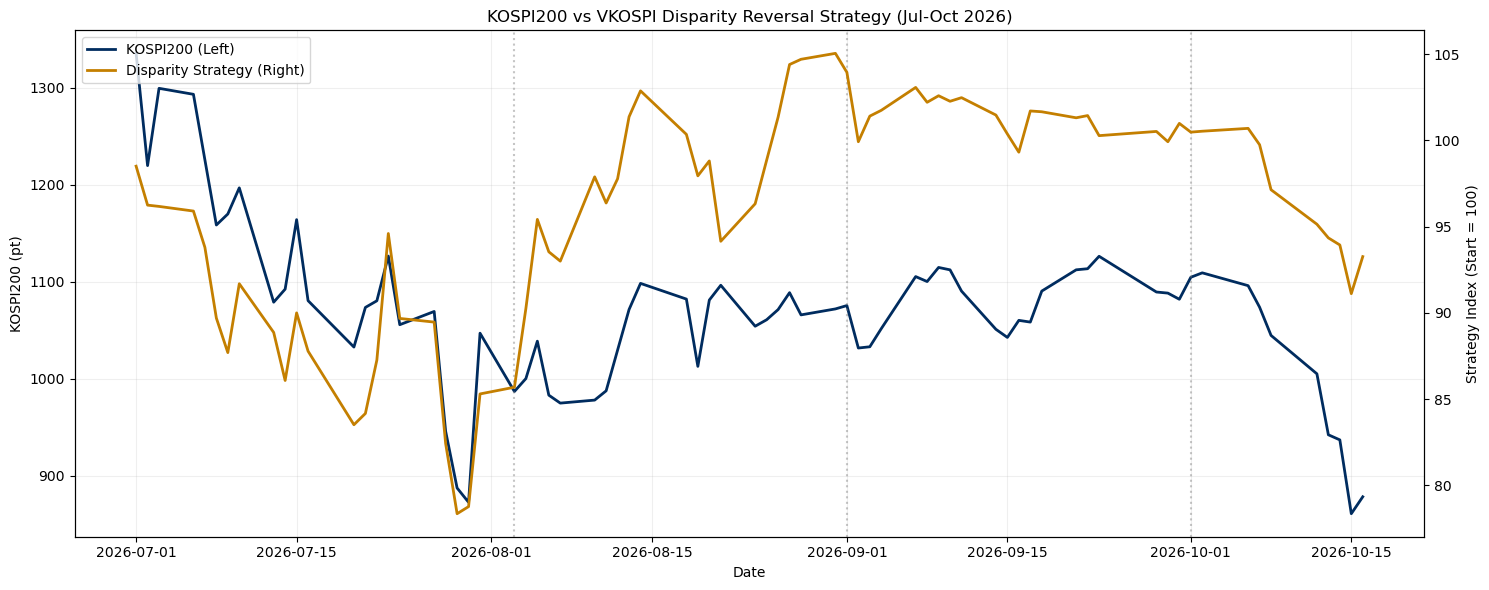

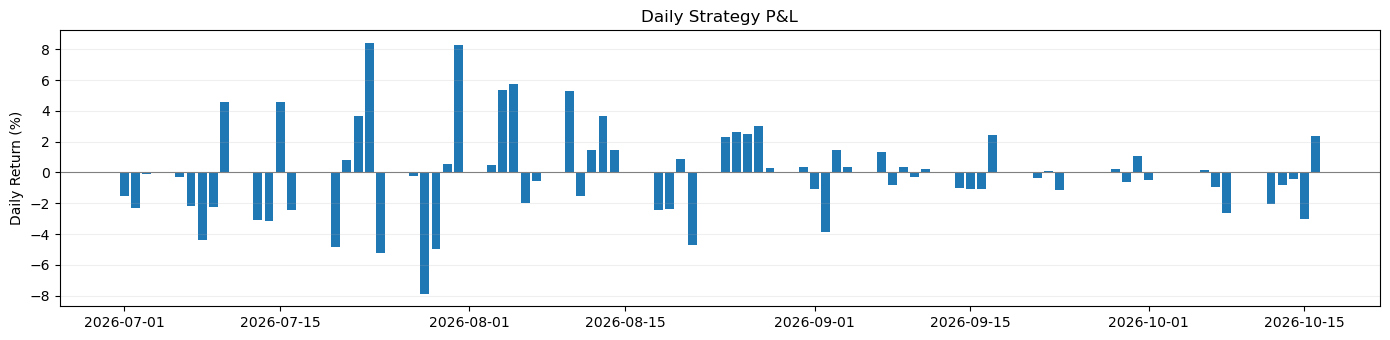

=== DAILY STRATEGY PERFORMANCE ===
기간: 2026-07-01 ~ 2026-10-16
최종 지수: 93.26
누적수익률: -6.74%
최종 평가손익: -674,257원
일별 종가기준 MDD: -20.45%


,holding_month,strategy_index,kospi200_index,daily_pnl_pts,daily_return,cumulative_return,daily_pnl_krw,cumulative_pnl_krw
date,,,,,,,,
2026-09-22 00:00:00,2026-09,101.43,80.16,+0.13,+0.13%,+1.43%,"+12,833","+143,304"
2026-09-23 00:00:00,2026-09,100.27,81.08,-1.16,-1.15%,+0.27%,"-116,325","+26,980"
2026-09-28 00:00:00,2026-09,100.51,78.43,+0.24,+0.24%,+0.51%,"+24,390","+51,370"
2026-09-29 00:00:00,2026-09,99.92,78.35,-0.60,-0.59%,-0.08%,"-59,633","-8,263"
2026-09-30 00:00:00,2026-09,100.98,77.89,+1.06,+1.06%,+0.98%,"+106,240","+97,977"
2026-10-01 00:00:00,2026-10,100.47,79.52,-0.51,-0.50%,+0.47%,"-50,645","+47,333"
2026-10-02 00:00:00,2026-10,100.53,79.85,+0.05,+0.05%,+0.53%,"+5,346","+52,679"
2026-10-06 00:00:00,2026-10,100.69,78.90,+0.17,+0.16%,+0.69%,"+16,509","+69,188"
2026-10-07 00:00:00,2026-10,99.74,77.30,-0.95,-0.94%,-0.26%,"-94,891","-25,703"


Saved: C:\Users\jesst\oos_vkospi_results\oos_daily_strategy_nav.csv


In [29]:
## 참고 -  7월 ~ 10월 16일까지, 포트폴리오의 PnL과


# ============================================================
# VKOSPI Disparity Strategy - Daily NAV (2026 Jul-Oct 16)
# 기존 OOS 노트북 마지막 셀에 추가
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

INITIAL_CAPITAL = 10_000_000  # 가상 투자원금: 1,000만원
INITIAL_INDEX = 100.0
FEE = ONE_WAY_COST_BPS / 10000

# 1. 종목별 일별 종가 매트릭스
close_wide = prices.pivot(
    index="date", columns="ticker", values="close"
).sort_index()

sessions = pd.DatetimeIndex(ks.index).sort_values()
records = []
base_nav = INITIAL_INDEX

# 2. 월별 포트폴리오를 일별로 평가
for _, m in monthly.sort_values("entry_date").iterrows():

    month = m["holding_month"]
    entry = pd.Timestamp(m["entry_date"])
    end = pd.Timestamp(m["exit_or_mark_date"])
    realized = m["status"] == "REALIZED"

    # 실현월: 다음 달 첫 거래일 시가에 청산하므로 해당 날짜 제외
    # 10월: 마지막 거래일 종가까지 포함
    days = sessions[
        (sessions >= entry) &
        ((sessions < end) if realized else (sessions <= end))
    ]

    holdings = trades[
        (trades["holding_month"] == month) &
        (trades["filled"] == True)
    ].copy()

    if bool(m["invested"]) and not holdings.empty:

        holdings = holdings.set_index("ticker")
        tickers = holdings.index.tolist()

        buy = holdings["entry_open"].astype(float)
        weights = holdings["weight_target"].astype(float)

        # 보유 종목의 일별 종가
        px = close_wide.reindex(
            index=days, columns=tickers
        )

        # 없는 가격은 임의로 보간하지 않음
        bad = px.isna() | (px <= 0)
        if bad.any().any():
            missing = bad.stack()
            missing = missing[missing].index.tolist()
            raise ValueError(
                f"{month}: 보유 종목 가격 결측 {missing[:10]}"
            )

        # 최초 5%씩 편입 후 비중은 자연스럽게 변함
        stock_returns = px.div(buy, axis=1) - 1

        gross_returns = stock_returns.mul(
            weights, axis=1
        ).sum(axis=1)

        # 매수 비용은 진입일에 반영
        entry_cost = FEE * weights.sum()

        period_nav = base_nav * (
            1 + gross_returns - entry_cost
        )

    else:
        # VKOSPI 미충족 시 현금 보유
        period_nav = pd.Series(base_nav, index=days)

    for d, value in period_nav.items():
        records.append({
            "date": d,
            "holding_month": month,
            "strategy_index": float(value)
        })

    # 다음 달 첫 거래일 시가에 기존 종목 청산
    # 기존 monthly 수익률은 진입·청산 비용 포함
    if realized:
        base_nav *= (1 + float(m["strategy_return"]))

# 3. 일별 지수 및 손익
daily_nav = pd.DataFrame(records)
daily_nav = daily_nav.sort_values("date").set_index("date")

daily_nav["kospi200_index"] = (
    INITIAL_INDEX
    * ks.loc[daily_nav.index, "close"]
    / ks.loc[pd.Timestamp(monthly.iloc[0]["entry_date"]), "open"]
)

daily_nav["daily_pnl_pts"] = (
    daily_nav["strategy_index"].diff()
)
daily_nav.iloc[
    0, daily_nav.columns.get_loc("daily_pnl_pts")
] = daily_nav["strategy_index"].iloc[0] - INITIAL_INDEX

daily_nav["daily_return"] = (
    daily_nav["strategy_index"].pct_change()
)
daily_nav.iloc[
    0, daily_nav.columns.get_loc("daily_return")
] = daily_nav["strategy_index"].iloc[0] / INITIAL_INDEX - 1

daily_nav["cumulative_return"] = (
    daily_nav["strategy_index"] / INITIAL_INDEX - 1
)

daily_nav["daily_pnl_krw"] = (
    daily_nav["daily_pnl_pts"]
    / INITIAL_INDEX * INITIAL_CAPITAL
)
daily_nav["cumulative_pnl_krw"] = (
    (daily_nav["strategy_index"] - INITIAL_INDEX)
    / INITIAL_INDEX * INITIAL_CAPITAL
)

# 4. 기존 월별 OOS 결과와 최종 NAV 대조
expected_final = float(monthly["strategy_nav"].iloc[-1]) * 100
actual_final = float(daily_nav["strategy_index"].iloc[-1])

assert np.isclose(
    actual_final, expected_final, atol=1e-7
), f"기존 결과와 불일치: {actual_final} vs {expected_final}"


# ==================================================
# Dual Axis: KOSPI200 vs Disparity Strategy
# ==================================================

fig, ax1 = plt.subplots(figsize=(15, 6))
ax2 = ax1.twinx()

# KOSPI200 실제 지수
kospi200 = ks.loc[daily_nav.index, "close"]

line1, = ax1.plot(
    daily_nav.index,
    kospi200,
    color="#002C5F",
    linewidth=2,
    label="KOSPI200 (Left)"
)

# 우리 전략 지수 (시작값 100)
line2, = ax2.plot(
    daily_nav.index,
    daily_nav["strategy_index"],
    color="#C47F00",
    linewidth=2,
    label="Disparity Strategy (Right)"
)

# 월별 리밸런싱 시점 표시
for d in monthly["entry_date"].iloc[1:]:
    ax1.axvline(
        pd.Timestamp(d),
        color="gray",
        linestyle=":",
        alpha=0.45
    )

ax1.set_xlabel("Date", color="black")
ax1.set_ylabel("KOSPI200 (pt)", color="black")
ax2.set_ylabel("Strategy Index (Start = 100)", color="black")

# 모든 축 눈금 및 숫자 검은색
ax1.tick_params(axis="both", colors="black")
ax2.tick_params(axis="both", colors="black")

# 축 테두리 검은색
for ax in [ax1, ax2]:
    for spine in ax.spines.values():
        spine.set_color("black")

# 제목 검은색
ax1.set_title(
    "KOSPI200 vs VKOSPI Disparity Reversal Strategy (Jul-Oct 2026)",
    color="black"
)

ax1.grid(alpha=0.2)
ax2.grid(False)

ax1.legend(
    [line1, line2],
    [line1.get_label(), line2.get_label()],
    loc="upper left"
)

plt.tight_layout()
plt.show()



# 6. 일별 손익 차트
fig, ax = plt.subplots(figsize=(14, 3.5))

ax.bar(
    daily_nav.index,
    daily_nav["daily_return"] * 100,
    width=0.8
)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Daily Strategy P&L")
ax.set_ylabel("Daily Return (%)")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# 7. 주요 결과 출력
print("=== DAILY STRATEGY PERFORMANCE ===")
print("기간:", daily_nav.index.min().date(),
      "~", daily_nav.index.max().date())
print(f"최종 지수: {actual_final:.2f}")
print(f"누적수익률: {daily_nav['cumulative_return'].iloc[-1]:+.2%}")
print(f"최종 평가손익: {daily_nav['cumulative_pnl_krw'].iloc[-1]:+,.0f}원")

running_max = daily_nav["strategy_index"].cummax()
daily_dd = daily_nav["strategy_index"] / running_max - 1
print(f"일별 종가기준 MDD: {daily_dd.min():.2%}")

display(
    daily_nav.tail(15).style.format({
        "strategy_index": "{:.2f}",
        "kospi200_index": "{:.2f}",
        "daily_pnl_pts": "{:+.2f}",
        "daily_return": "{:+.2%}",
        "cumulative_return": "{:+.2%}",
        "daily_pnl_krw": "{:+,.0f}",
        "cumulative_pnl_krw": "{:+,.0f}"
    })
)

# 8. CSV 저장
output_path = OUTPUT_DIR / "oos_daily_strategy_nav.csv"
daily_nav.to_csv(output_path, encoding="utf-8-sig")
print("Saved:", output_path.resolve())


## 과거 년도 함께 비교하기


OOS recomputed: -6.7426%
OOS notebook:  -6.7426%


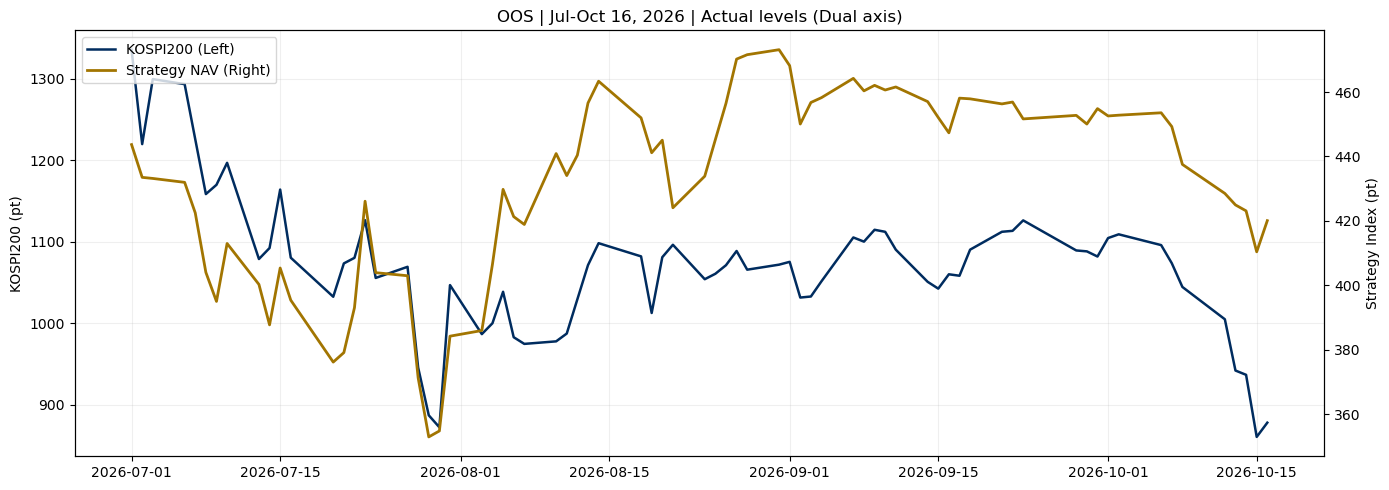

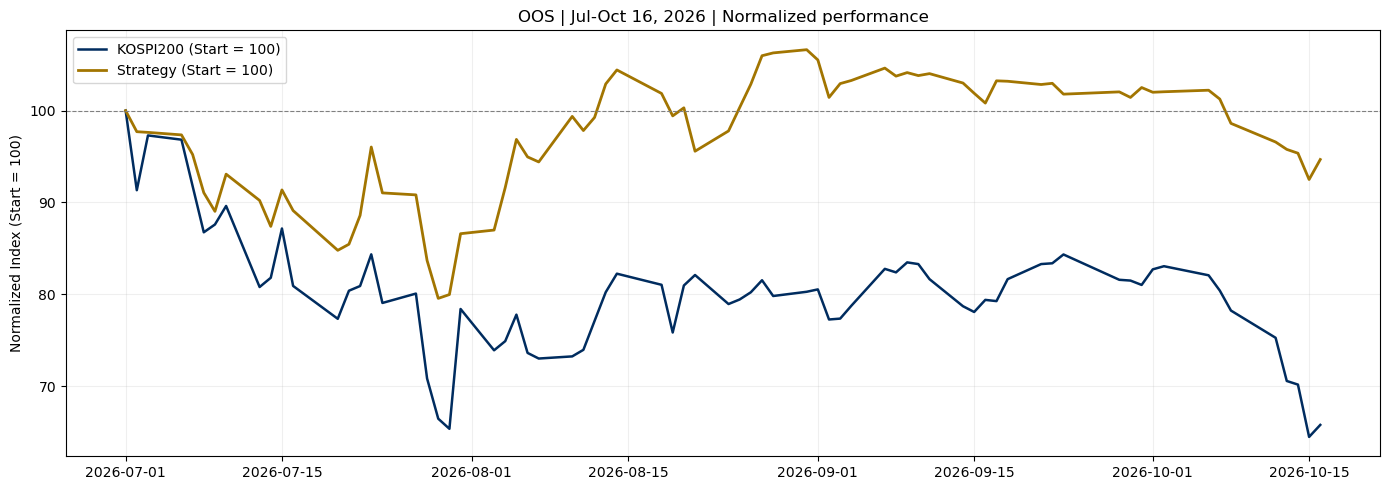

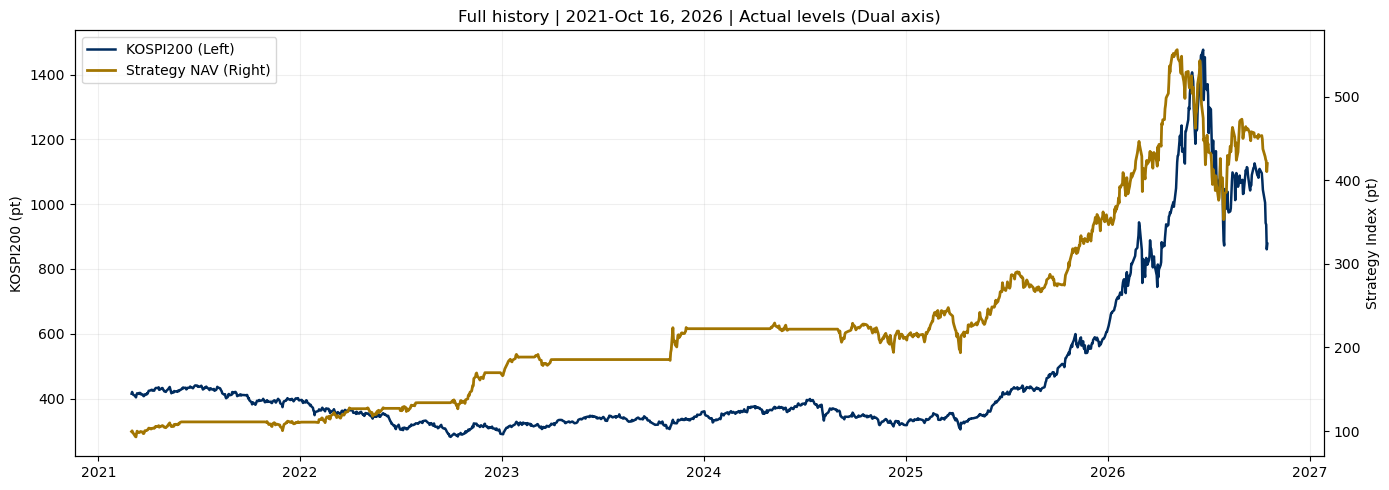

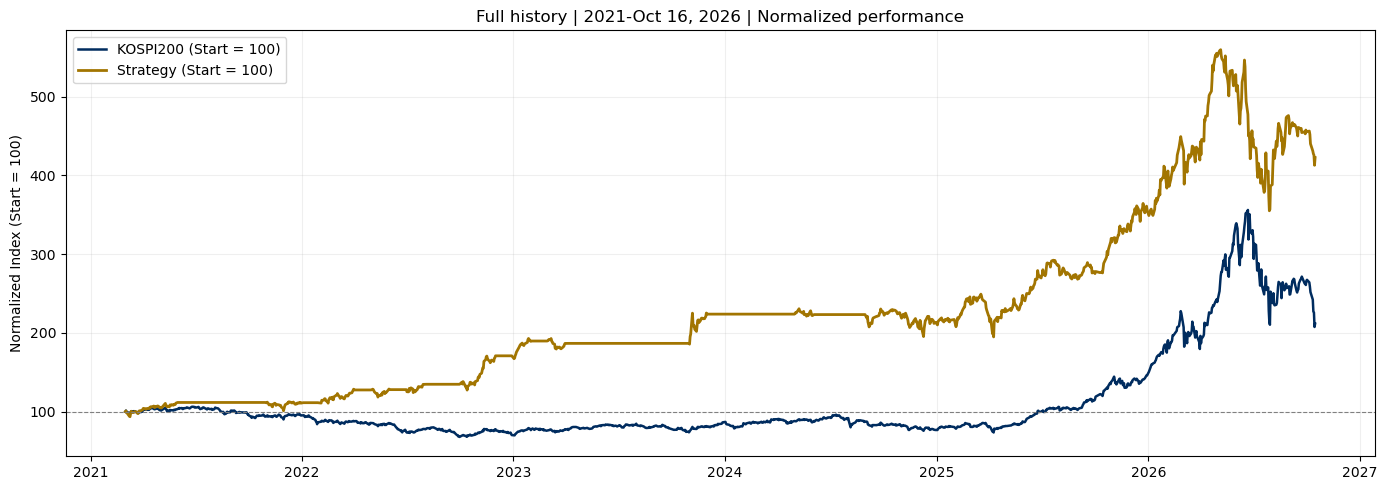

Saved: C:\Users\jesst\oos_vkospi_results\full_history_daily_strategy_vs_kospi200.csv


In [32]:
%run -i "./vkospi_comparison_chart_snippet.py"